# Chapitre 14 - Exercices 14.22 à 14.25

Ce notebook traite les derniers exercices du chapitre :

- **14.22** : PageRank (normalisation et méthode de la puissance) ;
- **14.23** : l'algorithme de factorisation en matrices non négatives (NMF) vu comme un
  algorithme MM (minoration–maximisation) ;
- **14.24** : NMF de rang 1 et ajustement proportionnel itératif ;
- **14.25** : NMF contre ACP sur les chiffres « 2 » manuscrits.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch14_non_supervise_complements as nsc
from esl import datasets
set_style()

## Exercice 14.22 : PageRank

**Énoncé (reformulé).**

(a) Montrer que la définition (14.108) implique que la somme des PageRanks $p_i$ vaut
$N$, le nombre de pages web.

(b) Écrire un programme calculant les PageRanks par la méthode de la puissance à partir
de la formulation (14.107), et l'appliquer au réseau de la figure 14.47 du livre.

### Rappels (section 14.10)

On note $L_{ij} = 1$ si la page $j$ pointe vers la page $i$ (0 sinon), et
$c_j = \sum_iL_{ij}$ le nombre de liens sortants de la page $j$. Les PageRanks sont
définis par la relation récursive (14.107) :
$$p_i = (1 - d) + d\sum_{j=1}^N\frac{L_{ij}}{c_j}\,p_j,$$
avec $d = 0{,}85$ ; matriciellement (14.108) :
$$p = (1-d)\,e + d\,LD_c^{-1}p,\qquad e = (1,\dots,1)^T,\quad D_c = \operatorname{diag}(c).$$
Chaque page $j$ distribue un « vote » total égal à $p_j$, réparti également entre les
$c_j$ pages vers lesquelles elle pointe.

### (a) La somme des PageRanks vaut $N$

On suppose que chaque page a au moins un lien sortant ($c_j \ge 1$, sinon $D_c^{-1}$
n'est pas défini). La somme de la colonne $j$ de $LD_c^{-1}$ vaut
$\sum_iL_{ij}/c_j = c_j/c_j = 1$, c'est-à-dire $e^TLD_c^{-1} = e^T$.

Multiplions (14.108) à gauche par $e^T$ :
$$e^Tp = (1-d)\,e^Te + d\,e^TLD_c^{-1}p = (1-d)N + d\,e^Tp.$$
Donc $(1 - d)\,e^Tp = (1-d)N$, et comme $d < 1$ :
$$\boxed{\sum_{i=1}^Np_i = e^Tp = N.}$$
La moyenne des PageRanks vaut 1 ; la normalisation $e^Tp = N$ utilisée pour écrire
(14.109) n'est donc pas une contrainte supplémentaire, elle découle de la définition.

### Le point de vue « chaîne de Markov »

Grâce à (a), on peut écrire $(1-d)e = (1-d)ee^Tp/N$, d'où $p = Ap$ avec
$$A = (1-d)\frac{ee^T}{N} + d\,LD_c^{-1}.\qquad(14.109)$$
Les coefficients de $A$ sont positifs et ses colonnes somment à 1 : $A$ est la matrice
de transition d'une chaîne de Markov (le **surfeur aléatoire** : depuis la page $j$, il
suit un lien sortant au hasard avec probabilité $d$, ou saute sur une page uniforme avec
probabilité $1-d$). $p/N$ est la loi stationnaire de cette chaîne, et la valeur propre 1
est la plus grande (en module) de $A$ : la **méthode de la puissance**
$p_k \leftarrow Ap_{k-1}$, $p_k \leftarrow Np_k/e^Tp_k$ (14.110) converge vers $p$.

### (b) Programme et vérification sur l'exemple du livre

La fonction `pagerank_power` implémente (14.110). On vérifie d'abord l'exemple de la
figure 14.46 (matrice (14.111)), pour lequel le livre donne
$\hat p = (1{,}49;\ 0{,}78;\ 1{,}58;\ 0{,}15)$.

In [2]:
L46 = np.array([[0, 0, 1, 0],
                [1, 0, 0, 0],
                [1, 1, 0, 1],
                [0, 0, 0, 0]])
p46, _ = nsc.pagerank_power(L46)
print("PageRanks (figure 14.46) :", p46.round(2))

PageRanks (figure 14.46) : [1.49 0.78 1.58 0.15]


**Réseau de la figure 14.47.** En lisant les flèches de la figure, on obtient les liens
(page source $\to$ page cible) :
$1\to2$, $1\to3$, $2\to3$, $3\to1$, $4\to1$, $4\to3$, $5\to3$, $6\to2$, $6\to5$.
Chaque page a au moins un lien sortant.

In [3]:
edges = [(1, 2), (1, 3), (2, 3), (3, 1), (4, 1), (4, 3), (5, 3), (6, 2), (6, 5)]
N6 = 6
L47 = np.zeros((N6, N6))
for j, i in edges:                       # la page j pointe vers la page i
    L47[i - 1, j - 1] = 1
print("matrice L :\n", L47.astype(int))
print("liens sortants c :", L47.sum(0).astype(int))

matrice L :
 [[0 0 1 1 0 0]
 [1 0 0 0 0 1]
 [1 1 0 1 1 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 1]
 [0 0 0 0 0 0]]
liens sortants c : [2 1 1 2 1 2]


In [4]:
p47, hist47 = nsc.pagerank_power(L47, d=0.85)
p47_lin = nsc.pagerank_linear(L47, d=0.85)
for k in range(N6):
    print("page %d : PageRank = %.4f" % (k + 1, p47[k]))
print("somme = %.6f ; écart à la résolution directe du système : %.1e"
      % (p47.sum(), np.abs(p47 - p47_lin).max()))

page 1 : PageRank = 2.1234
page 2 : PageRank = 1.1162
page 3 : PageRank = 2.2467
page 4 : PageRank = 0.1500
page 5 : PageRank = 0.2137
page 6 : PageRank = 0.1500
somme = 6.000000 ; écart à la résolution directe du système : 1.6e-13


**Interprétation.** Les pages 4 et 6 ne reçoivent aucun lien : elles ont le PageRank
minimal $1 - d = 0{,}15$. La page 5 n'est citée que par la page 6 (qui a 2 liens
sortants) : $p_5 = 0{,}15 + 0{,}85\times 0{,}15/2 = 0{,}214$. Les pages 1 et 3 se citent
mutuellement et la page 3 reçoit beaucoup de liens : ce sont les plus importantes.

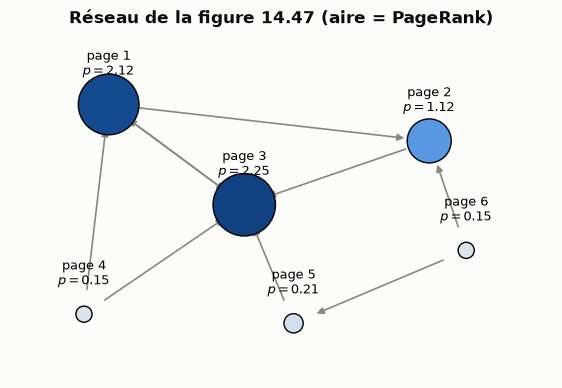

In [5]:
pos = np.array([[0.0, 2.0], [2.6, 1.6], [1.1, 0.9], [-0.2, -0.3], [1.5, -0.4], [2.9, 0.4]])
fig, ax = plt.subplots(figsize=(7, 4.5))
for j, i in edges:
    a, b = pos[j - 1], pos[i - 1]
    ax.annotate("", xy=b, xytext=a,
                arrowprops=dict(arrowstyle="-|>", color=GRAY, lw=1.2,
                                shrinkA=18, shrinkB=18))
ax.scatter(pos[:, 0], pos[:, 1], s=900 * p47, c=p47, cmap=SEQ, vmin=0, vmax=p47.max(),
           edgecolors="k", zorder=3)
for k in range(N6):
    ax.text(pos[k, 0], pos[k, 1] + 0.32, "page %d\n$p=%.2f$" % (k + 1, p47[k]),
            ha="center", fontsize=9)
ax.set_xlim(-0.8, 3.6); ax.set_ylim(-1.0, 2.8)
ax.set_axis_off()
ax.set_title("Réseau de la figure 14.47 (aire = PageRank)")
plt.show()

**Vitesse de convergence.** L'erreur de la méthode de la puissance décroît
géométriquement, au rythme du module de la deuxième valeur propre de $A$, qui est au
plus $d = 0{,}85$.

modules des valeurs propres de A : [1.    0.601 0.601 0.    0.    0.   ]


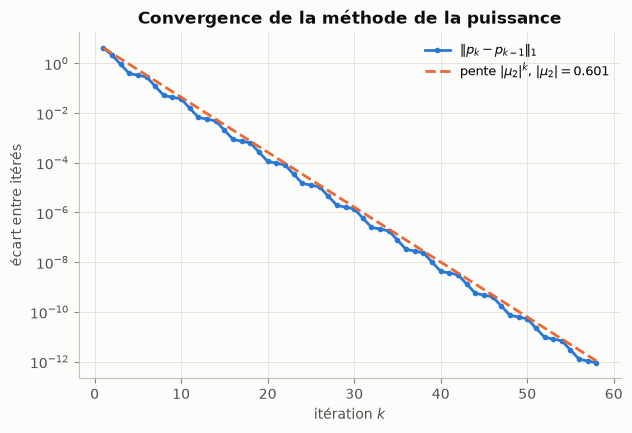

In [6]:
A47 = nsc.pagerank_matrix(L47)
ev = np.sort(np.abs(np.linalg.eigvals(A47)))[::-1]
print("modules des valeurs propres de A :", ev.round(4))
fig, ax = plt.subplots(figsize=(7, 4.5))
k = np.arange(1, len(hist47) + 1)
ax.semilogy(k, hist47, "o-", ms=3, color=BLUE, label=r"$\|p_k - p_{k-1}\|_1$")
ax.semilogy(k, hist47[0] * ev[1] ** (k - 1), "--", color=ORANGE,
            label=r"pente $|\mu_2|^k$, $|\mu_2| = %.3f$" % ev[1])
ax.set_xlabel("itération $k$")
ax.set_ylabel("écart entre itérés")
ax.set_title("Convergence de la méthode de la puissance")
ax.legend()
plt.show()

**Simulation du surfeur aléatoire.** On simule $200\,000$ pas de la chaîne de Markov
de matrice $A$ ; les fréquences de visite, multipliées par $N$, approchent les PageRanks.

In [7]:
rng = np.random.RandomState(0)
n_steps = 200_000
cum = np.cumsum(A47, axis=0)                 # colonne j : loi de la page suivante
u = rng.rand(n_steps)
state, visits = 0, np.zeros(N6)
for t_ in range(n_steps):
    state = np.searchsorted(cum[:, state], u[t_])
    visits[state] += 1
freq = N6 * visits / n_steps

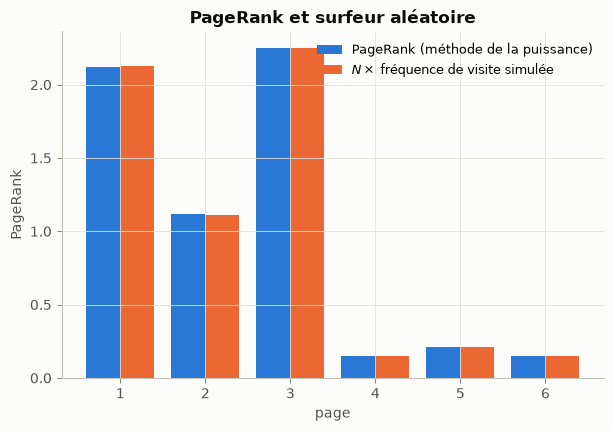

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
idx = np.arange(1, N6 + 1)
ax.bar(idx - 0.2, p47, 0.4, color=BLUE, label="PageRank (méthode de la puissance)")
ax.bar(idx + 0.2, freq, 0.4, color=ORANGE, label=r"$N\times$ fréquence de visite simulée")
ax.set_xlabel("page"); ax.set_ylabel("PageRank")
ax.set_xticks(idx)
ax.set_title("PageRank et surfeur aléatoire")
ax.legend()
plt.show()

> **À retenir.** Les colonnes de $LD_c^{-1}$ somment à 1, d'où
> $e^Tp = (1-d)N + d\,e^Tp$ et $\sum_ip_i = N$. Les PageRanks sont (à un facteur $N$) la
> loi stationnaire d'une chaîne de Markov, calculable par la méthode de la puissance.

## Exercice 14.23 : La NMF comme algorithme MM

**Énoncé (reformulé).** Une fonction $g(x, y)$ **minore** $f(x)$ si
$$g(x, y) \le f(x),\qquad g(x, x) = f(x)\qquad(14.119)$$
pour tous $x, y$. Alors $f$ ne décroît pas le long des itérations
$x^{s+1} = \operatorname{argmax}_x g(x, x^s)$ (14.120) : ce sont les algorithmes MM
(« minorer–maximiser »), dont l'algorithme EM est un cas particulier.

(a) Pour la log-vraisemblance (14.73)
$L(W,H) = \sum_{i,j}\big[x_{ij}\log\big(\sum_kw_{ik}h_{kj}\big) - \sum_kw_{ik}h_{kj}\big]$,
montrer, grâce à la concavité du logarithme, que pour $y_k\ge 0$ et $0 \le c_k\le 1$ avec
$\sum_kc_k = 1$ : $\log\big(\sum_ky_k\big) \ge \sum_kc_k\log(y_k/c_k)$, et en déduire
$$\log\Big(\sum_kw_{ik}h_{kj}\Big) \ge \sum_k\frac{a^s_{ikj}}{b^s_{ij}}
\log\Big(\frac{b^s_{ij}}{a^s_{ikj}}w_{ik}h_{kj}\Big),\quad a^s_{ikj} = w^s_{ik}h^s_{kj},\
b^s_{ij} = \sum_kw^s_{ik}h^s_{kj}.$$

(b) En déduire que, aux constantes près,
$g(W,H\mid W^s,H^s) = \sum_{i,j,k}x_{ij}\frac{a^s_{ikj}}{b^s_{ij}}(\log w_{ik} + \log h_{kj})
- \sum_{i,j,k}w_{ik}h_{kj}$ minore $L(W,H)$.

(c) Annuler les dérivées partielles de $g$ pour retrouver les mises à jour (14.74).

### Rappels

**Le modèle (section 14.6).** $X$ ($N\times p$, à coefficients $\ge 0$) est approchée
par $WH$ avec $W\ge 0$ ($N\times r$) et $H \ge 0$ ($r\times p$). $L(W,H)$ est la
log-vraisemblance (à une constante près) du modèle où $x_{ij}$ suit une loi de Poisson de
moyenne $(WH)_{ij}$. Les mises à jour de Lee et Seung (14.74) sont
$$w_{ik} \leftarrow w_{ik}\frac{\sum_jh_{kj}x_{ij}/(WH)_{ij}}{\sum_jh_{kj}},\qquad
h_{kj} \leftarrow h_{kj}\frac{\sum_iw_{ik}x_{ij}/(WH)_{ij}}{\sum_iw_{ik}}.$$

**Pourquoi MM fait croître $f$.** Si $x^{s+1}$ maximise $g(\cdot, x^s)$ :
$$f(x^{s+1}) \ \ge\ g(x^{s+1}, x^s)\ \ge\ g(x^s, x^s)\ =\ f(x^s),$$
la première inégalité par minoration, la deuxième par définition de $x^{s+1}$, l'égalité
par la condition de contact. Il suffit même que $x^{s+1}$ **augmente** $g(\cdot,x^s)$.

**Inégalité de Jensen.** Si $\phi$ est concave et $c_k \ge 0$ avec $\sum_kc_k = 1$, alors
$\phi\big(\sum_kc_kz_k\big) \ge \sum_kc_k\phi(z_k)$ : l'image d'une moyenne est au-dessus
de la moyenne des images (la corde est sous la courbe).

### (a) Minoration du logarithme

Supposons d'abord $c_k > 0$ pour tout $k$. On écrit $\sum_ky_k = \sum_kc_k\,(y_k/c_k)$,
une moyenne pondérée des $z_k = y_k/c_k$. Le logarithme étant concave, Jensen donne
$$\log\Big(\sum_ky_k\Big) = \log\Big(\sum_kc_k\frac{y_k}{c_k}\Big) \ge \sum_kc_k\log\frac{y_k}{c_k}.$$
Si certains $c_k$ sont nuls, on applique ce qui précède aux seuls $k$ avec $c_k > 0$ (les
termes $c_k\log(\cdot)$ correspondants sont nuls par convention $0\log(\cdot) = 0$), et
l'on utilise $\log\sum_{\text{tous}}y_k \ge \log\sum_{c_k>0}y_k$ (croissance du log, $y_k\ge0$).

On applique ce résultat, pour $(i,j)$ fixé, à $y_k = w_{ik}h_{kj}$ et
$c_k = a^s_{ikj}/b^s_{ij}$ : ces poids sont positifs et somment à 1 puisque
$\sum_ka^s_{ikj} = b^s_{ij}$. On obtient exactement
$$\log\Big(\sum_kw_{ik}h_{kj}\Big) \ge \sum_k\frac{a^s_{ikj}}{b^s_{ij}}
\log\Big(\frac{b^s_{ij}}{a^s_{ikj}}w_{ik}h_{kj}\Big).$$

**Cas d'égalité.** Pour $W = W^s$, $H = H^s$, on a $y_k/c_k = a^s_{ikj}b^s_{ij}/a^s_{ikj} =
b^s_{ij}$ pour tout $k$ : tous les $z_k$ sont égaux, et les deux membres valent
$\log b^s_{ij}$.

### (b) La fonction minorante

Multiplions l'inégalité de (a) par $x_{ij}\ge 0$, sommons sur $(i,j)$, et retranchons
$\sum_{i,j,k}w_{ik}h_{kj}$ des deux côtés :
$$L(W,H) \ \ge\ \tilde g(W,H\mid W^s,H^s) = \sum_{i,j,k}x_{ij}\frac{a^s_{ikj}}{b^s_{ij}}
\log\Big(\frac{b^s_{ij}}{a^s_{ikj}}w_{ik}h_{kj}\Big) - \sum_{i,j,k}w_{ik}h_{kj},$$
avec égalité en $(W^s,H^s)$ d'après le cas d'égalité. Donc $\tilde g$ minore $L$ au sens
de (14.119).

En développant $\log\big(\frac{b}{a}wh\big) = \log\frac{b}{a} + \log w + \log h$, on voit
que $\tilde g = g + \text{constante}$, où la constante
$\sum x_{ij}\frac{a^s_{ikj}}{b^s_{ij}}\log\frac{b^s_{ij}}{a^s_{ikj}}$ ne dépend que de
l'itéré courant, et
$$g(W,H\mid W^s,H^s) = \sum_{i,j,k}x_{ij}\frac{a^s_{ikj}}{b^s_{ij}}\big(\log w_{ik} +
\log h_{kj}\big) - \sum_{i,j,k}w_{ik}h_{kj}.$$
(Le $u_{ij}$ de l'énoncé du livre désigne $x_{ij}$.) Maximiser $g$ ou $\tilde g$ revient
au même.

### (c) Les mises à jour

On dérive $g$ par rapport à $w_{ik}$ (seuls les termes contenant $w_{ik}$ comptent) :
$$\frac{\partial g}{\partial w_{ik}} = \frac{1}{w_{ik}}\sum_jx_{ij}\frac{a^s_{ikj}}{b^s_{ij}}
- \sum_jh_{kj} = 0
\iff w_{ik} = \frac{\sum_jx_{ij}\,w^s_{ik}h^s_{kj}/b^s_{ij}}{\sum_jh_{kj}}.$$
À $H$ fixé, $g$ est une somme de fonctions **concaves** d'une seule variable
($\alpha\log w - \beta w$ avec $\alpha,\beta\ge0$), donc ce point critique est bien le
maximum, et il est positif.

La dérivée fait intervenir $H$ : on procède **par blocs**, comme dans (14.74). On met
d'abord à jour $W$ en fixant $H = H^s$ ; comme $b^s_{ij} = (W^sH^s)_{ij}$ :
$$w^{s+1}_{ik} = w^s_{ik}\frac{\sum_jh^s_{kj}x_{ij}/(W^sH^s)_{ij}}{\sum_jh^s_{kj}},$$
qui est la première ligne de (14.74). Puis on reconstruit la minorante au point
$(W^{s+1}, H^s)$ et, par symétrie des rôles de $W$ et $H$ :
$$\frac{\partial g}{\partial h_{kj}} = 0 \iff h^{s+1}_{kj} = h^s_{kj}\frac{\sum_iw^{s+1}_{ik}x_{ij}/(W^{s+1}H^s)_{ij}}{\sum_iw^{s+1}_{ik}},$$
la deuxième ligne de (14.74). Chaque demi-étape est une étape MM (pour $L$ vue comme
fonction de $W$ seul, puis de $H$ seul), donc $L$ ne décroît jamais.

### Vérifications numériques

Sur une petite matrice aléatoire, on vérifie (i) la minoration $\tilde g \le L$ en des
points tirés au hasard, (ii) l'égalité au point courant, (iii) la croissance monotone de
$L$ le long des itérations (14.74).

In [9]:
rng = np.random.RandomState(0)
Xs = rng.poisson(3.0, (30, 12)).astype(float)
r = 3
Ws, Hs = rng.uniform(0.2, 1.5, (30, r)), rng.uniform(0.2, 1.5, (r, 12))
gaps = []
for _ in range(500):
    W_, H_ = Ws * rng.uniform(0.2, 3, Ws.shape), Hs * rng.uniform(0.2, 3, Hs.shape)
    gaps.append(nsc.nmf_loglik(Xs, W_, H_) - nsc.nmf_minorizer(Xs, W_, H_, Ws, Hs))
print("min de L - g sur 500 points : %.4f (doit être >= 0)" % min(gaps))
print("L - g au point courant      : %.2e" % (nsc.nmf_loglik(Xs, Ws, Hs)
                                              - nsc.nmf_minorizer(Xs, Ws, Hs, Ws, Hs)))

min de L - g sur 500 points : 138.6141 (doit être >= 0)
L - g au point courant      : 0.00e+00


Visualisation de la minoration sur une coupe : on fait varier un seul coefficient
$w_{11} = t$, les autres étant fixés à l'itéré courant.

In [10]:
tt = np.linspace(0.05, 4, 200)
Lc, gc = [], []
for t_ in tt:
    W_ = Ws.copy(); W_[0, 0] = t_
    Lc.append(nsc.nmf_loglik(Xs, W_, Hs)); gc.append(nsc.nmf_minorizer(Xs, W_, Hs, Ws, Hs))
Lc, gc = np.array(Lc), np.array(gc)
t_new = Ws[0, 0] * (Hs[0] * Xs[0] / (Ws @ Hs)[0]).sum() / Hs[0].sum()

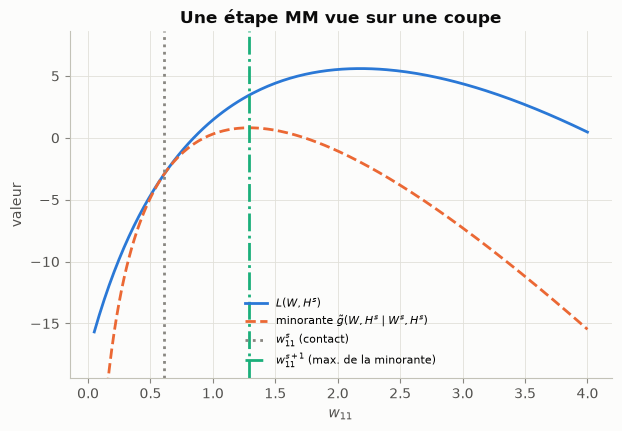

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(tt, Lc, color=BLUE, label=r"$L(W, H^s)$")
ax.plot(tt, gc, color=ORANGE, ls="--", label=r"minorante $\tilde g(W, H^s\mid W^s, H^s)$")
ax.axvline(Ws[0, 0], color=GRAY, ls=":", label="$w^s_{11}$ (contact)")
ax.axvline(t_new, color=COLORS[2], ls="-.", label="$w^{s+1}_{11}$ (max. de la minorante)")
ax.set_ylim(Lc.max() - 25, Lc.max() + 3)
ax.set_xlabel("$w_{11}$")
ax.set_ylabel("valeur")
ax.set_title("Une étape MM vue sur une coupe")
ax.legend(fontsize=8)
plt.show()

La minorante touche $L$ au point courant et reste en dessous ; son maximum (la mise à
jour (14.74)) donne une valeur de $L$ plus grande.

Croissance monotone de $L$ au fil des itérations :

nombre de décroissances de L : 0


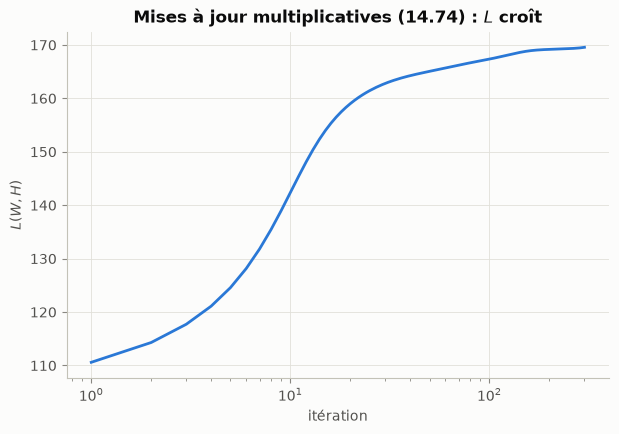

In [12]:
W_fit, H_fit, ll = nsc.nmf_kl(Xs, r, n_iter=300, random_state=0)
print("nombre de décroissances de L :", np.sum(np.diff(ll) < -1e-9))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, len(ll) + 1), ll, color=BLUE)
ax.set_xscale("log")
ax.set_xlabel("itération")
ax.set_ylabel("$L(W, H)$")
ax.set_title("Mises à jour multiplicatives (14.74) : $L$ croît")
plt.show()

> **À retenir.** La concavité du logarithme (Jensen) fournit une minorante séparable de
> la log-vraisemblance de Poisson, qui touche $L$ au point courant. Sa maximisation
> explicite redonne les mises à jour multiplicatives (14.74), qui font donc croître $L$
> à chaque étape et conservent la positivité.

## Exercice 14.24 : NMF de rang 1 et ajustement proportionnel itératif

**Énoncé (reformulé).** On considère la NMF (14.72) de rang $r = 1$ ; on note
$w_i = w_{i1}$ et $h_j = h_{1j}$.

(a) Montrer que les mises à jour (14.74) se réduisent à
$$w_i \leftarrow w_i\frac{\sum_jx_{ij}}{\sum_jw_ih_j},\qquad
h_j \leftarrow h_j\frac{\sum_ix_{ij}}{\sum_iw_ih_j}.\qquad(14.121)$$
C'est l'**ajustement proportionnel itératif** (*iterative proportional scaling*) pour le
modèle d'indépendance d'un tableau de contingence à deux entrées.

(b) Montrer que les itérés finaux ont une forme explicite, équivalente aux estimations
usuelles par lignes et colonnes du modèle d'indépendance (éq. (14.122)).

### (a) Réduction des mises à jour

Pour $r = 1$, $(WH)_{ij} = w_ih_j$. La première ligne de (14.74) devient
$$w_i \leftarrow w_i\frac{\sum_jh_j\,x_{ij}/(w_ih_j)}{\sum_jh_j}
= \frac{\sum_jx_{ij}}{\sum_jh_j} = w_i\frac{\sum_jx_{ij}}{\sum_jw_ih_j},$$
en simplifiant $h_j$ puis en multipliant numérateur et dénominateur par $w_i$. Par
symétrie, $h_j \leftarrow \sum_ix_{ij}/\sum_iw_i = h_j\sum_ix_{ij}/\sum_iw_ih_j$.
C'est (14.121).

**Interprétation.** Notons $x_{i+} = \sum_jx_{ij}$ (totaux de lignes), $x_{+j}$ (totaux
de colonnes) et $x_{++}$ le total général. La mise à jour de $w$ multiplie chaque ligne
de l'ajustement $\hat x_{ij} = w_ih_j$ par le facteur qui rend son total égal à $x_{i+}$ :
après cette étape, $\sum_jw_ih_j = x_{i+}$. Celle de $h$ ajuste de même les totaux de
colonnes. C'est exactement l'ajustement proportionnel itératif.

### (b) Forme explicite des itérés

Notons $W_+ = \sum_iw_i$ et $H_+ = \sum_jh_j$. Après une mise à jour de $w$ :
$w_i = x_{i+}/H_+$, donc $W_+ = x_{++}/H_+$. Après la mise à jour de $h$ qui suit :
$h_j = x_{+j}/W_+$. Mais alors $\sum_jh_j = x_{++}/W_+ = H_+$ : **la somme des $h$ n'a pas
changé**, donc une nouvelle mise à jour de $w$ redonne $w_i = x_{i+}/H_+$, inchangé. De
même pour $h$. **L'algorithme atteint son point fixe dès la première itération complète.**

En posant $c = W_+ = x_{++}/H_+ > 0$ (arbitraire, fixé par l'initialisation), le point
fixe s'écrit
$$w_i = c\,\frac{x_{i+}}{x_{++}},\qquad h_j = \frac{x_{+j}}{c},\qquad\text{d'où}\qquad
\hat x_{ij} = w_ih_j = \frac{x_{i+}\,x_{+j}}{x_{++}}.$$
On reconnaît les effectifs attendus sous l'hypothèse d'indépendance (ceux du test du
$\chi^2$), qui sont les estimateurs du maximum de vraisemblance du modèle d'indépendance :
probabilité de ligne $x_{i+}/x_{++}$ fois probabilité de colonne $x_{+j}/x_{++}$, fois
l'effectif total. Le facteur $c$ traduit la non-identifiabilité $(w, h) \to (cw, h/c)$.

> **Remarque.** Le livre écrit (14.122) avec $h_k = \frac1c\,x_{+k}/x_{++}$ ; avec cette
> écriture, le produit $w_ih_k = x_{i+}x_{+k}/x_{++}^2$ ne reproduit plus les totaux de
> lignes (sauf si $x_{++}=1$, c'est-à-dire pour un tableau de **fréquences**). La forme
> ci-dessus, $h_k = x_{+k}/c$, est celle qui est un point fixe de (14.121) pour un tableau
> d'effectifs ; les deux coïncident pour des fréquences.

### Vérification sur données réelles

On croise deux variables du jeu de données *marketing* du chapitre 14 (revenu en 9
classes et niveau d'études en 6 classes) et l'on applique la NMF de rang 1.

In [13]:
mk = datasets.load_marketing().dropna(subset=["Income", "Edu"])
tab = (mk.groupby(["Income", "Edu"]).size().unstack(fill_value=0)).to_numpy(float)
print("tableau de contingence (revenu x études), total = %d :\n" % tab.sum(), tab.astype(int))

tableau de contingence (revenu x études), total = 8907 :
 [[195 682 338 392  77  40]
 [ 22  70 281 298  66  34]
 [ 11  48 205 267  95  35]
 [  5  43 245 326 130  51]
 [  6  30 216 270 141  53]
 [  7  52 295 406 220 119]
 [  7  38 173 372 234 137]
 [  6  43 188 494 340 225]
 [  5  40 100 241 221 272]]


In [14]:
w1, h1, ll1 = nsc.nmf_kl(tab, 1, n_iter=5, random_state=0)
fit_nmf = w1 @ h1
fit_indep = np.outer(tab.sum(1), tab.sum(0)) / tab.sum()
print("log-vraisemblance après chaque itération :", ll1.round(6))
print("max |W H - x_i+ x_+j / x_++| = %.2e" % np.abs(fit_nmf - fit_indep).max())
c_hat = w1.sum()
w_th, h_th = nsc.independence_fit(tab, c=c_hat)
print("c = %.4f ; écart aux formules explicites : %.2e, %.2e"
      % (c_hat, np.abs(w1[:, 0] - w_th).max(), np.abs(h1[0] - h_th).max()))

log-vraisemblance après chaque itération : [38672.836169 38672.836169 38672.836169 38672.836169 38672.836169]
max |W H - x_i+ x_+j / x_++| = 5.68e-14
c = 2514.7769 ; écart aux formules explicites : 5.68e-14, 0.00e+00


La log-vraisemblance est constante dès la première itération : le point fixe est atteint
en un seul passage, et coïncide avec les effectifs attendus sous indépendance. Les
résidus de Pearson $(x_{ij} - \hat x_{ij})/\sqrt{\hat x_{ij}}$ montrent ensuite ce que le
modèle d'indépendance (rang 1) ne capture pas : la forte association revenu–études.

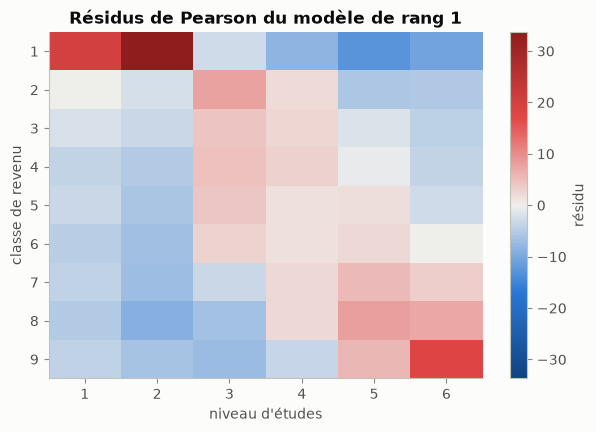

In [15]:
resid = (tab - fit_indep) / np.sqrt(fit_indep)
vmax = np.abs(resid).max()
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(resid, cmap=DIV, vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(range(1, tab.shape[1] + 1))
ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(range(1, tab.shape[0] + 1))
ax.set_xlabel("niveau d'études"); ax.set_ylabel("classe de revenu")
ax.set_title("Résidus de Pearson du modèle de rang 1")
ax.grid(False)
plt.colorbar(im, ax=ax, label="résidu")
plt.show()

> **À retenir.** En rang 1, la NMF de Poisson est le modèle d'indépendance d'un tableau
> de contingence ; ses mises à jour sont l'ajustement proportionnel itératif, qui
> converge en une itération vers $\hat x_{ij} = x_{i+}x_{+j}/x_{++}$, avec
> $w_i = c\,x_{i+}/x_{++}$ et $h_j = x_{+j}/c$.

## Exercice 14.25 : NMF et ACP sur les chiffres « 2 »

**Énoncé (reformulé).** Ajuster une NMF à l'ensemble des « 2 » de la base de chiffres
manuscrits (données *zip*), avec 25 éléments de base, et la comparer à une ACP à 24
composantes (plus la moyenne). Dans les deux cas, afficher les matrices $W$ et $H$ comme
dans la figure 14.33 du livre.

### Préparation des données

Les images zip sont en $16\times16$ pixels, à niveaux de gris dans $[-1, 1]$ ($-1$ :
fond blanc). La NMF exige des données positives : on les ramène dans $[0, 1]$ par
$x \mapsto (x+1)/2$, de sorte que 0 corresponde au fond et 1 à l'encre.

In [16]:
Xz, yz = datasets.load_zip("train")
X2 = (Xz[yz == 2] + 1) / 2
print("nombre de « 2 » :", X2.shape[0], "; pixels :", X2.shape[1])

nombre de « 2 » : 731 ; pixels : 256


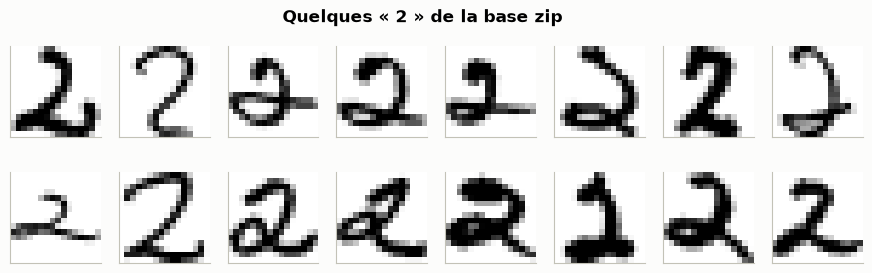

In [17]:
fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for ax, img in zip(axes.ravel(), X2[:16]):
    ax.imshow(img.reshape(16, 16), cmap="gray_r", vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Quelques « 2 » de la base zip", fontweight="bold")
plt.show()

### Les deux modèles

- **NMF** : $X \approx WH$ avec $W$ ($731\times25$) et $H$ ($25\times256$) positifs, par
  les mises à jour multiplicatives (14.74), 400 itérations. Chaque ligne de $H$ est une
  image de base ; la ligne $i$ de $W$ donne les poids de l'image $i$. Comme
  $WH = (WD)(D^{-1}H)$ pour toute diagonale $D > 0$, on normalise ensuite chaque image de
  base à un maximum de 1 (cela rend les poids comparables).
- **ACP** : $X \approx \mathbf 1\bar x^T + U_{24}D_{24}V_{24}^T$. Pour l'écrire sous la
  même forme $WH$, on prend pour $H$ la moyenne $\bar x$ et les 24 directions
  principales ($25\times 256$), et pour $W$ la colonne de 1 suivie des 24 scores
  $UD$ ($731\times25$). Ici $H$ et $W$ ont des signes quelconques.

In [18]:
W_nmf, H_nmf, ll_nmf = nsc.nmf_kl(X2, 25, n_iter=400, random_state=0)
scale = H_nmf.max(1)                 # WH inchangé : on normalise chaque image de base
H_nmf, W_nmf = H_nmf / scale[:, None], W_nmf * scale[None, :]
xbar = X2.mean(0)
U, d, Vt = np.linalg.svd(X2 - xbar, full_matrices=False)
H_pca = np.vstack([xbar, Vt[:24]])
W_pca = np.column_stack([np.ones(len(X2)), U[:, :24] * d[:24]])
print("log-vraisemblance NMF : départ %.0f, fin %.0f" % (ll_nmf[0], ll_nmf[-1]))

log-vraisemblance NMF : départ -100657, fin -77753


Comparaison avec scikit-learn (même critère de Kullback–Leibler, mêmes mises à jour
multiplicatives), seulement pour contrôler notre implémentation : les log-vraisemblances
atteintes doivent être du même ordre (les optima locaux diffèrent).

In [19]:
from sklearn.decomposition import NMF   # pour comparaison seulement

sk = NMF(25, beta_loss="kullback-leibler", solver="mu", init="random", max_iter=400,
         random_state=0).fit(X2)
print("L(W, H) : notre NMF = %.0f, scikit-learn = %.0f"
      % (ll_nmf[-1], nsc.nmf_loglik(X2, sk.transform(X2), sk.components_)))

L(W, H) : notre NMF = -77753, scikit-learn = -77843


### Affichage de $H$ : les images de base

Pour la NMF, on ordonne les images de base par poids moyen décroissant. Pour l'ACP, la
première case est la moyenne, puis les directions principales (échelle de couleur
divergente : rouge positif, bleu négatif).

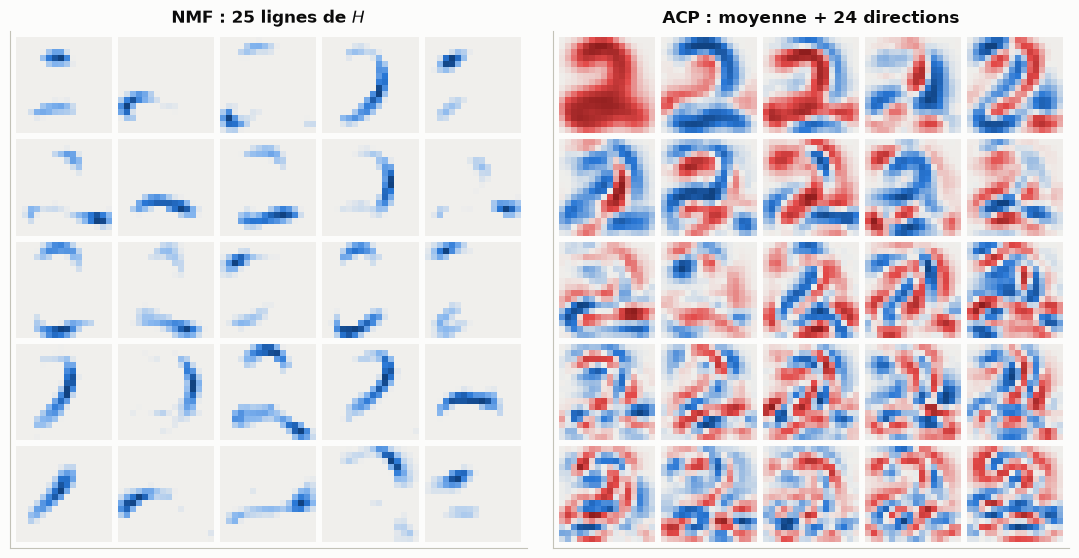

In [20]:
def montage(ax, Hm, cmap, symmetric):
    tiles = np.ones((5 * 17 + 1, 5 * 17 + 1)) * np.nan
    for k in range(25):
        a, b = divmod(k, 5)
        img = Hm[k].reshape(16, 16)
        if symmetric:
            img = img / np.abs(img).max()
        else:
            img = img / img.max()
        tiles[1 + 17 * a:17 * (a + 1), 1 + 17 * b:17 * (b + 1)] = img
    vmin = -1 if symmetric else 0
    ax.imshow(tiles, cmap=cmap, vmin=vmin, vmax=1)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

order_nmf = np.argsort(W_nmf.mean(0))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
montage(axes[0], H_nmf[order_nmf], SEQ, symmetric=False)
axes[0].set_title("NMF : 25 lignes de $H$")
montage(axes[1], H_pca, DIV, symmetric=True)
axes[1].set_title("ACP : moyenne + 24 directions")
plt.tight_layout()
plt.show()

Les images de base de la NMF sont **localisées** : chacune représente un morceau de
trait (boucle du haut, diagonale, barre du bas à différentes positions). Celles de l'ACP
sont **globales** et de signes mêlés : après la moyenne, chaque direction modifie toute
l'image en ajoutant de l'encre à un endroit et en en retirant ailleurs. C'est
l'observation de Lee et Seung rapportée dans le livre : la NMF apprend des « parties ».

### Affichage de $W$ et reconstruction d'un chiffre (à la manière de la figure 14.33)

Pour un « 2 » donné, la ligne correspondante de $W$ (25 coefficients, disposés en
$5\times5$ comme les images de base) et la reconstruction $\sum_kw_{ik}h_k$.

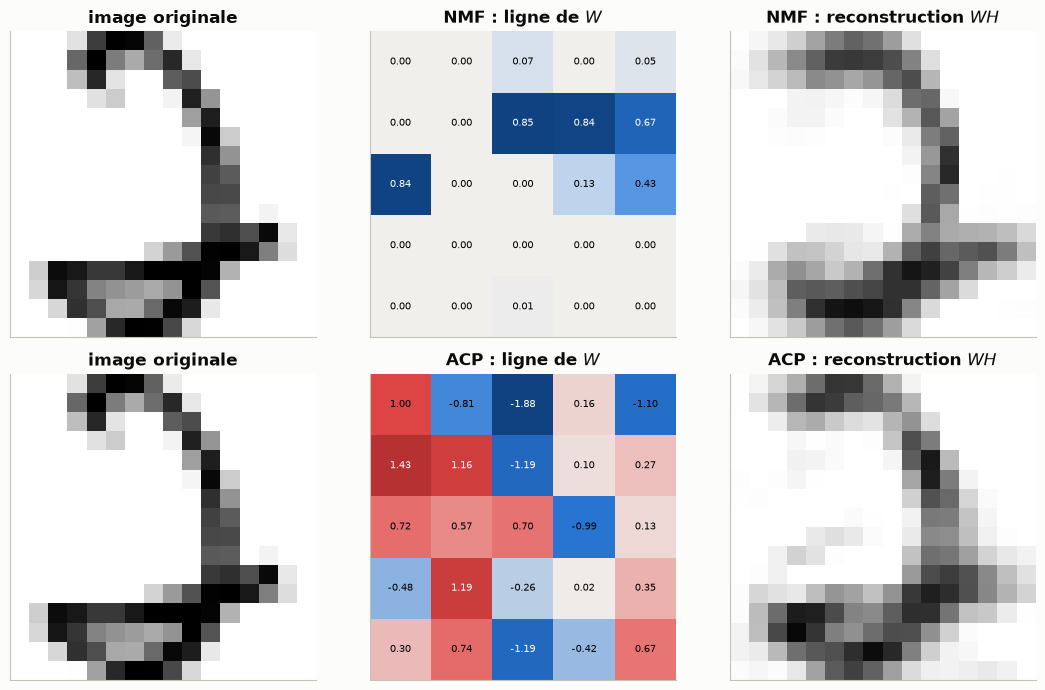

In [21]:
i0 = 7
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
rows = [("NMF", W_nmf[i0, order_nmf], W_nmf @ H_nmf, SEQ, False),
        ("ACP", W_pca[i0], W_pca @ H_pca, DIV, True)]
for r_, (name, wrow, recon, cmap, sym) in enumerate(rows):
    ax = axes[r_, 0]
    ax.imshow(X2[i0].reshape(16, 16), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title("image originale")
    ax = axes[r_, 1]
    vm = np.abs(wrow).max()
    im = ax.imshow(wrow.reshape(5, 5), cmap=cmap, vmin=-vm if sym else 0, vmax=vm)
    for k in range(25):
        ax.text(k % 5, k // 5, "%.2f" % wrow[k], ha="center", va="center", fontsize=7,
                color="w" if abs(wrow[k]) > 0.6 * vm else "k")
    ax.set_title("%s : ligne de $W$" % name)
    ax = axes[r_, 2]
    ax.imshow(np.clip(recon[i0], 0, 1).reshape(16, 16), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title("%s : reconstruction $WH$" % name)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.show()

Les coefficients NMF sont positifs et **creux** : quelques parties suffisent à
reconstruire le chiffre (on additionne des traits). Les coefficients ACP sont de signes
quelconques : la reconstruction résulte de compensations entre directions.

Quantifions la parcimonie (proportion de coefficients presque nuls, inférieurs à 1 % du
maximum de leur matrice) et la qualité de reconstruction des deux modèles.

In [22]:
def sparsity(M):
    return np.mean(np.abs(M) < 0.01 * np.abs(M).max())

R_nmf, R_pca = W_nmf @ H_nmf, W_pca @ H_pca
print("%-5s %14s %14s %16s" % ("", "creux de W", "creux de H", "erreur quadr. moy."))
print("%-5s %14.2f %14.2f %16.4f" % ("NMF", sparsity(W_nmf), sparsity(H_nmf),
                                     np.mean((X2 - R_nmf) ** 2)))
print("%-5s %14.2f %14.2f %16.4f" % ("ACP", sparsity(W_pca[:, 1:]), sparsity(H_pca[1:]),
                                     np.mean((X2 - R_pca) ** 2)))

          creux de W     creux de H erreur quadr. moy.
NMF             0.57           0.84           0.0422
ACP             0.04           0.08           0.0266


L'ACP, optimale au sens des moindres carrés pour un rang donné (théorème d'Eckart–Young),
a l'erreur quadratique la plus faible ; la NMF, qui optimise un autre critère (Poisson)
sous contrainte de positivité, a une erreur environ 1,6 fois plus grande, mais fournit
des facteurs beaucoup plus creux et interprétables. C'est le prix de la contrainte de
positivité.

Distribution des valeurs des matrices $H$ :

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist((H_nmf / H_nmf.max()).ravel(), bins=50, color=BLUE)
axes[0].set_title("NMF : coefficients de $H$ (normalisés)")
axes[1].hist((H_pca[1:] / np.abs(H_pca[1:]).max()).ravel(), bins=50, color=ORANGE)
axes[1].set_title("ACP : coefficients des 24 directions")
for ax in axes:
    ax.set_xlabel("valeur"); ax.set_ylabel("effectif")
plt.tight_layout()
plt.show()